# 3. Preparação da Base Hidrográfica Ottocodificada (BHO)

## 3.1 Introdução

Este notebook realiza a preparação da Base Hidrográfica Ottocodificada (BHO) da Bacia do Rio Doce. A partir da camada de trechos de drenagem disponibilizada pela Agência Nacional de Águas e Saneamento Básico (ANA), são executadas as etapas de carregamento, inspeção, recorte espacial, visualização e exportação da rede hidrográfica, gerando a camada vetorial que será utilizada nas análises hidrológicas e ambientais das próximas etapas do projeto.

## 3.2 Objetivos

Ao final deste notebook será possível:

- carregar a Base Hidrográfica Ottocodificada (BHO);
- verificar a consistência dos dados vetoriais;
- explorar os atributos da camada de trechos de drenagem;
- recortar a hidrografia utilizando o limite da Bacia do Rio Doce;
- visualizar os resultados do processamento;
- exportar a camada vetorial para utilização nas próximas etapas do projeto.

## 3.3 Bibliotecas

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

## 3.4 Estrutura dos Diretórios

In [2]:
def encontrar_raiz_projeto():
    """Localiza a raiz do projeto a partir do diretório de execução."""
    inicio = Path.cwd().resolve()

    for pasta in (inicio, *inicio.parents):
        # Critério principal: diretório Git do repositório.
        if (pasta / ".git").exists():
            return pasta

        # Alternativa para cópias do projeto sem a pasta .git.
        if (
            (pasta / "README.md").is_file()
            and (pasta / "notebooks").is_dir()
            and (pasta / "dados").is_dir()
        ):
            return pasta

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto. "
        "Abra o Jupyter dentro do repositório Bacia_Rio_Doce."
    )


ROOT = encontrar_raiz_projeto()

In [3]:
DIR_DADOS = ROOT / "dados"

DIR_BRUTOS = DIR_DADOS / "brutos"
DIR_PROCESSADOS = DIR_DADOS / "processados"

DIR_ANA = DIR_BRUTOS / "ANA"
DIR_BHO = DIR_ANA / "BHO"

DIR_HIDROGRAFIA = DIR_PROCESSADOS / "hidrografia"
DIR_AREA = DIR_PROCESSADOS / "area_estudo"

print("Estrutura de diretórios configurada.")

Estrutura de diretórios configurada.


## 3.5 Dados de entrada

Arquivo utilizados:

- bacia_rio_doce.gpkg
- bho_2017_v_01_05_50k.gpkg

Fontes:

- Agência Nacional de Águas e Saneamento Básico (ANA)


Formatos:

- GeoPackage (GPKG)

Sistemas de referência esperados:

- BHO: EPSG:4674 (SIRGAS 2000)
- Área de estudo: EPSG:4674 (SIRGAS 2000)

## 3.6 Leitura

### Hidrografia (BHO)

In [4]:
INPUT_BHO = DIR_BHO / "bho_2017_v_01_05_50k.gpkg"
LAYER_TRECHOS = "pgh_output.geoft_bho_trecho_drenagem"

if not INPUT_BHO.exists():
    raise FileNotFoundError(f"Arquivo da BHO não encontrado: {INPUT_BHO}")

trechos = gpd.read_file(
    INPUT_BHO,
    layer=LAYER_TRECHOS
)

C:\Users\claud\anaconda3\envs\AmbGEO\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


A Base Hidrográfica Ottocodificada (BHO) representa a rede hidrográfica brasileira estruturada segundo o método de Ottocodificação, permitindo a identificação da conectividade entre trechos de drenagem e o desenvolvimento de análises hidrológicas em diferentes escalas.

### Área de estudo

In [5]:
INPUT_AREA = DIR_AREA / "bacia_rio_doce.gpkg"

if not INPUT_AREA.exists():
    raise FileNotFoundError(f"Arquivo do limite da bacia não encontrado: {INPUT_AREA}")

bacia_rio_doce = gpd.read_file(INPUT_AREA)

## 3.7 Exploração

### Hidrografia

In [6]:
trechos.head()

,drn_pk,cotrecho,noorigem,nodestino,cocursodag,cobacia,nucomptrec,nudistbact,nudistcdag,nuareacont,...,nudistbacc,nuareabacc,nuordemcda,nucompcda,nunivotto,nunivotcda,nustrahler,dedominial,dsversao,geometry
0,36442,36442,10778,10788,49448,4944831,8.102693,3754.699218,42.005741,49.637425,...,3712.693477,7834.314657,4.0,223.062662,7,5.0,3.0,Internacional,BHO bho_2017_v_01_05_50k de 2018-06-22,"MULTILINESTRING ((-72.87813 1.0222, -72.8698 1..."
1,92196,92196,67373,65997,41884,41884,39.986292,824.300668,0.000000,511.875748,...,824.300668,511.875748,4.0,39.986292,5,5.0,1.0,Estadual,BHO bho_2017_v_01_05_50k de 2018-06-22,"MULTILINESTRING ((-53.13287 1.74453, -53.13848..."
2,13317,13317,89583,89597,722,7229973,7.105098,639.183627,560.386161,32.535022,...,78.797466,40231.413523,2.0,621.891128,7,3.0,3.0,Estadual,BHO bho_2017_v_01_05_50k de 2018-06-22,"MULTILINESTRING ((-46.95188 -5.56922, -46.9518..."
3,8721,8721,64603,63764,82746,827461,50.888327,1592.710437,0.000000,199.563718,...,1592.710437,663.769031,4.0,113.907008,6,5.0,2.0,Estadual,BHO bho_2017_v_01_05_50k de 2018-06-22,"MULTILINESTRING ((-53.759 -28.43729, -53.7592 ..."
4,9577,9577,65292,64603,827462,827462,25.190457,1643.598764,0.000000,105.529176,...,1643.598764,105.529176,5.0,25.190457,6,6.0,1.0,Estadual,BHO bho_2017_v_01_05_50k de 2018-06-22,"MULTILINESTRING ((-53.5983 -28.4636, -53.59769..."


In [7]:
print("Número de feições:", len(trechos))
print("Geometrias válidas:", trechos.is_valid.all())
print("Limites:", trechos.total_bounds)
print("Geometria das feições:", trechos.geom_type.value_counts())
print("CRS:", trechos.crs)
print("Colunas:", trechos.columns)
trechos.info()

Número de feições: 115169
Geometrias válidas: True
Limites: [-81.338452  -54.2935102 -34.7933849  12.4685686]
Geometria das feições: MultiLineString    115169
Name: count, dtype: int64
CRS: EPSG:4674
Colunas: Index(['drn_pk', 'cotrecho', 'noorigem', 'nodestino', 'cocursodag', 'cobacia',
       'nucomptrec', 'nudistbact', 'nudistcdag', 'nuareacont', 'nuareamont',
       'nogenerico', 'noligacao', 'noespecif', 'noriocomp', 'nooriginal',
       'cocdadesag', 'nutrjus', 'nudistbacc', 'nuareabacc', 'nuordemcda',
       'nucompcda', 'nunivotto', 'nunivotcda', 'nustrahler', 'dedominial',
       'dsversao', 'geometry'],
      dtype='str')
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 115169 entries, 0 to 115168
Data columns (total 28 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   drn_pk      115169 non-null  int32   
 1   cotrecho    115169 non-null  int32   
 2   noorigem    115169 non-null  int32   
 3   nodestino   115169 non

#### Significado de alguns atributos importantes

- `cobacia`/`cocursodag`: códigos de Ottocodificação (identificam a posição hierárquica do trecho na rede de drenagem);
                       
- `nustrahler`: ordem de Strahler (classifica a hierarquia do curso d'água — relevante para priorizar trechos principais na análise de recuperação);

- `dedominial`: domínio do corpo hídrico (Federal/Estadual/Internacional — define quem tem competência de gestão/licenciamento, algo bem relevante num projeto de recuperação ambiental);
                      
- `nucomptrec`: comprimento do trecho na geometria original da BHO, antes do recorte pela área de estudo. Esse atributo não é recalculado após o `clip` e, portanto, não deve ser utilizado diretamente para calcular o comprimento da rede dentro da bacia.                         

### Área de estudo

In [8]:
print("Número de feições:", len(bacia_rio_doce))
print("Geometrias válidas na área:", bacia_rio_doce.is_valid.all())
print("CRS da área de estudo:", bacia_rio_doce.crs)

Número de feições: 1
Geometrias válidas na área: True
CRS da área de estudo: EPSG:4674


## 3.8 Processamento

### Recorte espacial

In [9]:
# O recorte exige que as camadas estejam no mesmo sistema de referência.
print("CRS da BHO:", trechos.crs)
print("CRS da bacia:", bacia_rio_doce.crs)

assert trechos.crs is not None, "A camada da BHO não possui CRS definido."
assert bacia_rio_doce.crs is not None, "A camada da bacia não possui CRS definido."
assert trechos.crs == bacia_rio_doce.crs, (
    "Os CRS das camadas são diferentes. Reprojete as camadas antes do recorte."
)

CRS da BHO: EPSG:4674
CRS da bacia: EPSG:4674


In [10]:
trechos_rio_doce = gpd.clip(
    trechos,
    bacia_rio_doce
)

### Validação do resultado

In [11]:
print(f"Feições antes do recorte: {len(trechos):,}")
print(f"Feições depois do recorte: {len(trechos_rio_doce):,}")
print("CRS do resultado:", trechos_rio_doce.crs)
print("Tipos geométricos após o recorte:")
print(trechos_rio_doce.geom_type.value_counts())
trechos_rio_doce.info()

Feições antes do recorte: 115,169
Feições depois do recorte: 997
CRS do resultado: EPSG:4674
Tipos geométricos após o recorte:
LineString         996
MultiLineString      1
Name: count, dtype: int64
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 997 entries, 84221 to 82856
Data columns (total 28 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   drn_pk      997 non-null    int32   
 1   cotrecho    997 non-null    int32   
 2   noorigem    997 non-null    int32   
 3   nodestino   997 non-null    int32   
 4   cocursodag  994 non-null    str     
 5   cobacia     997 non-null    str     
 6   nucomptrec  997 non-null    float64 
 7   nudistbact  994 non-null    float64 
 8   nudistcdag  994 non-null    float64 
 9   nuareacont  997 non-null    float64 
 10  nuareamont  997 non-null    float64 
 11  nogenerico  979 non-null    str     
 12  noligacao   979 non-null    str     
 13  noespecif   979 non-null    str     
 14  noriocomp 

In [12]:
print("Geometrias válidas na BHO:", trechos.is_valid.all())
print("Geometrias válidas na bacia:", bacia_rio_doce.is_valid.all())
print("Geometrias válidas após o recorte:", trechos_rio_doce.is_valid.all())
print("Há geometrias vazias no resultado:", trechos_rio_doce.geometry.is_empty.any())
print("Há geometrias nulas no resultado:", trechos_rio_doce.geometry.isna().any())

assert not trechos_rio_doce.empty, "O recorte não retornou feições."
assert not trechos_rio_doce.geometry.isna().any(), "O resultado contém geometrias nulas."
assert not trechos_rio_doce.geometry.is_empty.any(), "O resultado contém geometrias vazias."
assert trechos_rio_doce.is_valid.all(), "O resultado contém geometrias inválidas."

Geometrias válidas na BHO: True
Geometrias válidas na bacia: True
Geometrias válidas após o recorte: True
Há geometrias vazias no resultado: False
Há geometrias nulas no resultado: False


A operação de recorte espacial alterou a composição geométrica de parte das feições, resultando predominantemente em LineString. As geometrias foram mantidas conforme produzidas pela operação, sem conversão artificial do tipo geométrico.

Os atributos `nucomptrec`, `nuareacont` e `nuareamont` correspondem às feições originais da BHO nacional.

Após o clip, a geometria representa apenas a parte do trecho dentro da bacia, mas esses atributos não são recalculados automaticamente. Portanto, não devem ser usados diretamente para calcular comprimentos ou áreas dentro da bacia, especialmente nos trechos que cruzam seu limite.

## 3.9 Visualização

### Bacia do Rio Doce sobre a hidrografia do Brasil

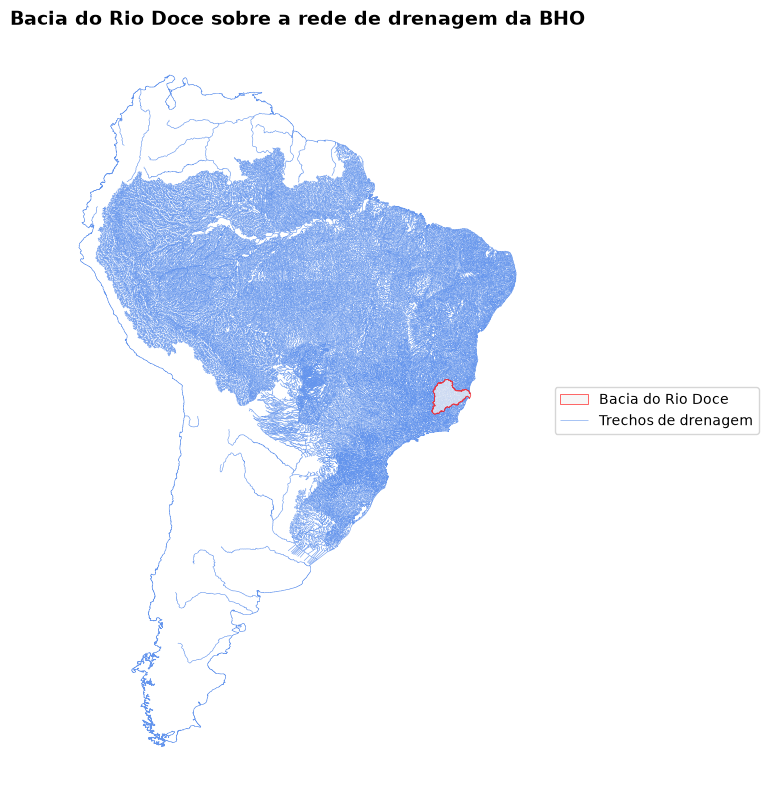

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))

# Área da bacia
bacia_rio_doce.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="red",
    linewidth=0.6,
    alpha=0.7,
    label="Bacia do Rio Doce",
    zorder=2
)

# Hidrografia
trechos.plot(
    ax=ax,
    color="cornflowerblue",
    linewidth=0.4,
    label="Trechos de drenagem",
    zorder=1
)

ax.set_title(
    "Bacia do Rio Doce sobre a rede de drenagem da BHO",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# Remove os eixos
ax.set_axis_off()

# Legenda fora do mapa
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True
)

plt.tight_layout()
plt.show()

### Bacia recortada

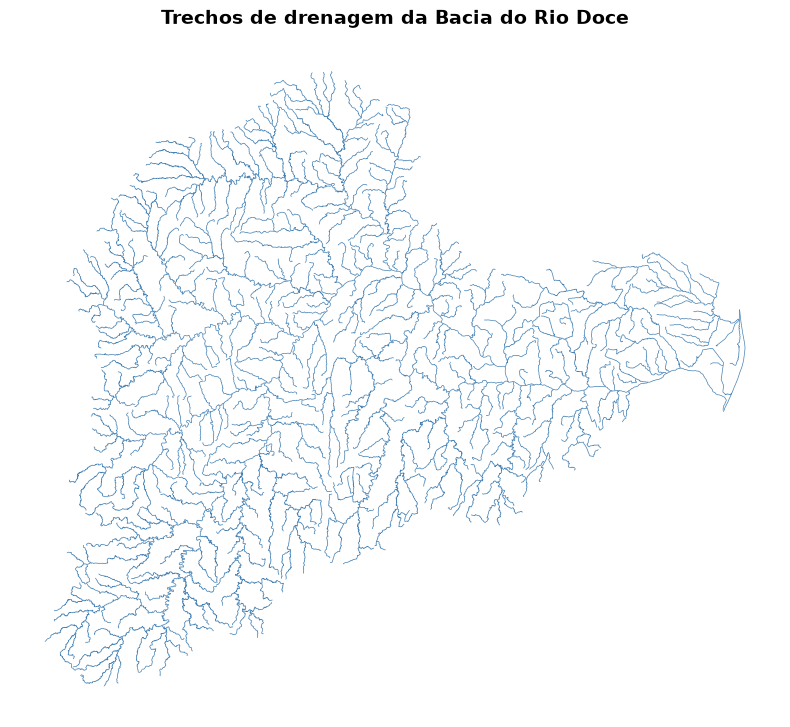

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))

trechos_rio_doce.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.5
)

ax.set_title(
    "Trechos de drenagem da Bacia do Rio Doce",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 3.10 Exportação e salvamento

In [15]:
OUTPUT_HIDRO = DIR_HIDROGRAFIA / "trecho_drenagem_rio_doce.gpkg"

# Garante que o diretório de saída exista.
DIR_HIDROGRAFIA.mkdir(parents=True, exist_ok=True)

trechos_rio_doce.to_file(
    OUTPUT_HIDRO,
    driver="GPKG"
)

print(
    "Arquivo salvo com sucesso em: "
    f"{OUTPUT_HIDRO.relative_to(ROOT)}"
)

Arquivo salvo com sucesso em: dados\processados\hidrografia\trecho_drenagem_rio_doce.gpkg


### Verificar arquivo gerado

In [16]:
# Teste de integridade do arquivo exportado

assert OUTPUT_HIDRO.is_file(), (
    f"Arquivo não encontrado: {OUTPUT_HIDRO}"
)

# Reabre o arquivo salvo no disco
hidro_teste = gpd.read_file(OUTPUT_HIDRO)

# Verifica o conteúdo
print("Arquivo:", OUTPUT_HIDRO.relative_to(ROOT))
print(f"Tamanho: {OUTPUT_HIDRO.stat().st_size / 1024**2:.2f} MB")
print(f"Número de feições: {len(hidro_teste):,}")
print("CRS:", hidro_teste.crs)
print("Tipos geométricos:")
print(hidro_teste.geom_type.value_counts())
print("Geometrias válidas:", hidro_teste.is_valid.all())
print("Geometrias nulas:", hidro_teste.geometry.isna().sum())
print("Geometrias vazias:", hidro_teste.geometry.is_empty.sum())

# Compara a camada reaberta com o GeoDataFrame original
assert len(hidro_teste) == len(trechos_rio_doce), (
    "A quantidade de feições do arquivo salvo é diferente da original."
)
assert hidro_teste.crs == trechos_rio_doce.crs, (
    "O CRS do arquivo salvo é diferente do original."
)
assert hidro_teste.geometry.notna().all(), (
    "O arquivo contém geometrias nulas."
)

print("\nTeste concluído: arquivo reaberto e verificações básicas aprovadas.")

Arquivo: dados\processados\hidrografia\trecho_drenagem_rio_doce.gpkg
Tamanho: 6.73 MB
Número de feições: 997
CRS: EPSG:4674
Tipos geométricos:
MultiLineString    997
Name: count, dtype: int64
Geometrias válidas: True
Geometrias nulas: 0
Geometrias vazias: 0

Teste concluído: arquivo reaberto e verificações básicas aprovadas.


## 3.12 Conclusão

Neste notebook foi preparado o trecho de drenagem da Bacia do Rio Doce. A camada vetorial foi carregada, inspecionada, recortada utilizando o limite da área de estudo e foi exportada em formato GeoPackage, preservando todos os metadados espaciais necessários para as próximas etapas do projeto. Esta camada servirá como base para as análises hidrológicas, cálculo de APPs, integração com o Modelo Digital de Elevação e demais procedimentos de geoprocessamento desenvolvidos ao longo do projeto. 